# Joint (theta_J, theta_x, theta_y) SBI diffusion experiments

Full pipeline, in order: generate CB data for random (theta_J, theta_x,
theta_y) triples, load it into features, train a conditional diffusion
model, sample its posterior, and check predictions against ground truth.
The 10,000-run dataset was already generated offline; everything from
feature loading onward runs live in this notebook.

See `../analysis/plan.html` for where this sits in the overall plan,
`../analysis/index.html` for how the target (theta_J, theta_x, theta_y)
and the [-1, 1] range were decided, and `../analysis/findings.html` for the
2026-09-19 session summary (also linked from the last cell of this notebook).

# H = theta_J&middot;(X&otimes;X) + theta_x&middot;(X&otimes;I + I&otimes;X) + theta_y&middot;(Y&otimes;I + I&otimes;Y)

This is the Hamiltonian every cell below is trying to characterize: a
system qubit coupled to one environment qubit. `X`, `Y`, `I` are the
single-qubit Pauli/identity matrices. **theta_J** is the two-qubit XX
coupling between system and environment; **theta_x** and **theta_y** are
X-axis and Y-axis fields felt equally by both qubits.

One coupling cycle applies `U = exp(-i*delta*H)` to the system+environment
pair (see `couple_with_env` in `../DiffusionCB/cb_harness.py`) &mdash; delta
is fixed at 1.0 and folded into theta_J/theta_x/theta_y, so there's no
separate delta to solve for (see `../analysis/index.html` for why).
Everything from Step 1 onward exists to recover (theta_J, theta_x,
theta_y) from raw Cycle Benchmarking data generated under this H.

### Step 1 — Data

Import the sweep module. The full 10,000-run dataset was already generated
offline via `run_joint_datagen.py` (background, ~hours); this cell doesn't
regenerate it, just brings `sweep_joint` and everything `cb_harness`
re-exports (np, pd, Path, ...) into scope for the rest of the notebook.

In [1]:
from joint_sweep import *  # brings in sweep_joint, plus everything cb_harness re-exports (np, pd, Path, ...)
'''n_runs = 100
base_cfg = CBConfig(n_sys_qubits=1, n_env=0, shots=1024, m_list=(2,4,6,8,12,16), L=30, K=30, label="CB_cycle", rng=np.random.default_rng(0))
sweep_joint(num_runs=n_runs, base_config=base_cfg, cycle="I")
print(f"DONE: ")'''

# ran offline data gen script for 10000 files

'n_runs = 100\nbase_cfg = CBConfig(n_sys_qubits=1, n_env=0, shots=1024, m_list=(2,4,6,8,12,16), L=30, K=30, label="CB_cycle", rng=np.random.default_rng(0))\nsweep_joint(num_runs=n_runs, base_config=base_cfg, cycle="I")\nprint(f"DONE: ")'

### Step 2 — Sanity check

List the generated files and inspect one: confirm the count (10,000), the
shape (540 rows = 3 Paulis x 6 m values x 30 twirls per run), and that the
columns look right (theta_J/x/y, P, m, l, f_pml, ...) before trusting any
of it downstream.

In [2]:
files = sorted(Path("data").glob("*.parquet"))
print(f"{len(files)} files\n")

df = pd.read_parquet(files[0])
print("shape:", df.shape)
print("\ncolumns and dtypes:")
print(df.dtypes)

df.head(10)

10000 files

shape: (540, 13)

columns and dtypes:
noisetype         str
theta_J       float64
theta_x       float64
theta_y       float64
seed            int64
P                 str
m               int64
l               int64
f_pml         float64
n_plus          int64
n_minus         int64
pauli_sign      int64
twirl_seq      object
dtype: object


,noisetype,theta_J,theta_x,theta_y,seed,P,m,l,f_pml,n_plus,n_minus,pauli_sign,twirl_seq
0,memory,-0.460427,-0.918053,-0.966945,0,X,2,0,-0.921875,984,40,-1,"[Z, Y, Y]"
1,memory,-0.460427,-0.918053,-0.966945,0,X,2,1,-0.593750,208,816,1,"[X, X, I]"
2,memory,-0.460427,-0.918053,-0.966945,0,X,2,2,0.562500,800,224,1,"[I, I, I]"
3,memory,-0.460427,-0.918053,-0.966945,0,X,2,3,-0.921875,984,40,-1,"[Z, Y, Z]"
4,memory,-0.460427,-0.918053,-0.966945,0,X,2,4,-0.947266,997,27,-1,"[Y, Y, Z]"
5,memory,-0.460427,-0.918053,-0.966945,0,X,2,5,-0.929688,988,36,-1,"[Y, Y, Y]"
6,memory,-0.460427,-0.918053,-0.966945,0,X,2,6,0.828125,936,88,1,"[Y, Z, X]"
7,memory,-0.460427,-0.918053,-0.966945,0,X,2,7,-0.919922,41,983,1,"[Z, Y, I]"
8,memory,-0.460427,-0.918053,-0.966945,0,X,2,8,0.814453,929,95,1,"[X, Z, Y]"
9,memory,-0.460427,-0.918053,-0.966945,0,X,2,9,0.824219,934,90,1,"[I, Z, Y]"


### Step 3 — Features and the forward diffusion step

`load_joint_features` collapses each run's 540 raw rows into 36 summary
features (mean+var of f_pml per Pauli x m) and returns train/test tensors.
`y` is `abs(theta_J, theta_x, theta_y)`, not signed -- see
`../analysis/findings.html` for why (raw CB data encodes coupling
magnitude, not sign). `add_noise` is the fixed forward corruption step (no
learning) that the training loop uses to make noisy targets.

In [3]:
import numpy as np
import pandas as pd
from pathlib import Path
import torch

def load_joint_features(data_dir="data", test_fraction=0.2, seed=0):
    '''Xtr/Xte : (N, 36) standardized input features.
    ytr/yte : (N, 3)  columns are (|theta_J|, |theta_x|, |theta_y|), NOT
              standardized -- abs() applied below, so range is now [0, 1],
              not [-1, 1].

    Why abs(): raw CB features only encode theta's MAGNITUDE, not its sign
    -- verified by correlation check: corr(feature, signed theta) ~0.02 across
    all 36 features, but corr(feature, |theta|) up to 0.65. This is a real
    physics limit (sign isn't observable from system-only measurements when
    the environment is inaccessible), not a training bug -- see
    ../analysis/findings.html for the full writeup.'''

    #1. load all files in data
    files = sorted(Path(data_dir).glob("*.parquet"))
    df = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)

    #2. find mean, var for each CB run. Each CB run hedre is 30 times so we will have 30*6 times m values and 3 paulis = 540 rows. now each of the 30 runs we will just avg and get mean and var so only two values rather than 540 which means we will have 540/30 = 18 and 18*2 = 36 features
    per_training_keys = ["seed", "theta_J", "theta_x", "theta_y"]
    aggregated_data = df.groupby(per_training_keys + ["P", "m"])["f_pml"].agg(["mean", "var"]).reset_index()
    features = aggregated_data.pivot_table(index=per_training_keys, columns=["P", "m"], values=["mean", "var"])
    features.columns = [f"{stat}_{P}{m}" for stat, P, m in features.columns]

    features = features.reset_index()

    #3, X (NX36) and y (NX3=theta_Jm theta_x, theta_y)
    features_cols = [c for c in features.columns if c not in per_training_keys]
    X = features[features_cols].to_numpy(dtype="float32")
    y = np.abs(features[["theta_J", "theta_x", "theta_y"]].to_numpy(dtype="float32"))

    #4. split (fixed seed)
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(X))
    n_test_samples = int(test_fraction * len(X))
    test_idx, train_idx = idx[:n_test_samples], idx[n_test_samples:]

    #5 standardize X on TRAIN samples and y left alone as its already standardized to [-1, 1]
    mu, sd = X[train_idx].mean(0), X[train_idx].std(0)
    Xn = (X-mu)/sd

    Xtr = torch.tensor(Xn[train_idx])
    ytr = torch.tensor(y[train_idx])
    Xte = torch.tensor(Xn[test_idx])
    yte = torch.tensor(y[test_idx])

    return Xtr, ytr, Xte, yte, features_cols


'''FORWARD (fixed, no learning) -- the closed-form noise jump:
    x_t = sqrt(alpha_bar_t) * x_0 + sqrt(1 - alpha_bar_t) * eps, where eps ~ N(0,1)
'''
def add_noise(x_0, t, alpha_bar):
    ab = alpha_bar[t].unsqueeze(1)
    eps = torch.randn_like(x_0)
    x_t = ab.sqrt()*x_0 + (1-ab).sqrt()*eps
    return x_t, eps

### Step 4 — The model

`NoisePredictor`: the network that looks at a noisy guess `x_t`, the
current diffusion step `t`, and the 36 conditioning features `c`, and
predicts the noise baked into `x_t`. `target_dim=3` (theta_J, theta_x,
theta_y) is the only real change from the original 1-D delta-only version
-- everything else (the reverse-diffusion math) is dimension-agnostic and
needed no change.

In [4]:
# Noise predictor the model
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parents[1] / "DiffusionCB"))

import torch
import torch.nn as nn

from conditional_diffusion import time_step_embed, noise_lookup  # unchanged for 3-D, reuse don't duplicate

class NoisePredictor(nn.Module):
    def __init__(self, conditional_dim=36, target_dim=3, hidden=128, time_step_dim=16):
        super().__init__()
        self.time_step_dim= time_step_dim
        input_dim = target_dim + time_step_dim + conditional_dim
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, target_dim), # target_dim are 3 here
        )
    def forward(self, x_t, t, c):
        t_embd = time_step_embed(t, dim=self.time_step_dim)
        h = torch.cat([x_t, t_embd, c], dim=1)
        return self.net(h)

### Step 5 — The training loop

`train_joint_diffusion`: standard noise-regression training (random step
`t`, corrupt `y_train`, ask the model to predict the injected noise, MSE
loss), with a held-out validation split used to pick the best-epoch
weights, not just the last epoch's.

In [5]:
import copy

def train_joint_diffusion(Xtr, ytr, alpha_bar, T=100, hidden=128, epochs=5000, lr=3e-4, val_frac=0.15, seed=0, verbose=True):
    torch.manual_seed(seed)
    g=torch.Generator().manual_seed(seed)
    shuffled_idx=torch.randperm(len(Xtr), generator=g)
    n_val = int(val_frac*len(Xtr))
    val_idx, train_idx = shuffled_idx[:n_val], shuffled_idx[n_val:]

    x_train, y_train = Xtr[train_idx], ytr[train_idx]
    x_val, y_val = Xtr[val_idx], ytr[val_idx]

    t_val = torch.randint(0, T, (len(y_val),), generator=g)
    x_t_val, eps_val = add_noise(y_val, t_val, alpha_bar)
    best_val_loss = float("inf")
    model = NoisePredictor(conditional_dim=Xtr.shape[1], target_dim=ytr.shape[1], hidden=hidden)
    opt = torch.optim.Adam(model.parameters(), lr=lr)

    for epoch in range(epochs):
        model.train()
        t = torch.randint(0, T, (len(y_train),))
        x_t, eps = add_noise(y_train, t, alpha_bar)
        eps_hat = model(x_t, t, x_train)
        loss = ((eps-eps_hat)**2).mean()
        opt.zero_grad(); loss.backward(); opt.step()
                          
        model.eval()
        with torch.no_grad():
            val_loss = ((eps_val - model(x_t_val, t_val, x_val))**2).mean().item()
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_state = copy.deepcopy(model.state_dict())
                best_epoch = epoch
            if verbose and epoch % 100 == 0:
                print(f"epoch {epoch:3d}  train MSE {loss.item():.4f}  val MSE {val_loss:.4f}")
    model.load_state_dict(best_state)
    if verbose:
        print(f"restored best (by val MSE): {best_val_loss:.4f} at epoch {best_epoch}")

    return model

### Step 6 — Driver: actually train

Loads the real data, trains the model. Current run: 5000 epochs, best val
MSE ~0.058 (still improving slightly at the end -- more epochs are cheap,
~1 min for 5000; more training data isn't worth generating, diminishing
returns already hit around 4000 rows).

In [6]:
# train the model
alpha, alpha_bar = noise_lookup(T=100)
Xtr, ytr, Xte, yte, feature_cols = load_joint_features()
print(f"Xtr {tuple(Xtr.shape)}  ytr {tuple(ytr.shape)}  Xte {tuple(Xte.shape)}  yte {tuple(yte.shape)}")

model = train_joint_diffusion(Xtr, ytr, alpha_bar)


Xtr (8000, 36)  ytr (8000, 3)  Xte (2000, 36)  yte (2000, 3)
epoch   0  train MSE 1.0155  val MSE 0.9985
epoch 100  train MSE 0.2380  val MSE 0.2153
epoch 200  train MSE 0.1671  val MSE 0.1677
epoch 300  train MSE 0.1426  val MSE 0.1404
epoch 400  train MSE 0.1186  val MSE 0.1205
epoch 500  train MSE 0.1109  val MSE 0.1113
epoch 600  train MSE 0.1062  val MSE 0.1074
epoch 700  train MSE 0.1004  val MSE 0.1016
epoch 800  train MSE 0.0925  val MSE 0.0970
epoch 900  train MSE 0.0900  val MSE 0.0933
epoch 1000  train MSE 0.0876  val MSE 0.0908
epoch 1100  train MSE 0.0849  val MSE 0.0878
epoch 1200  train MSE 0.0844  val MSE 0.0863
epoch 1300  train MSE 0.0840  val MSE 0.0835
epoch 1400  train MSE 0.0746  val MSE 0.0820
epoch 1500  train MSE 0.0768  val MSE 0.0813
epoch 1600  train MSE 0.0735  val MSE 0.0782
epoch 1700  train MSE 0.0673  val MSE 0.0768
epoch 1800  train MSE 0.0724  val MSE 0.0760
epoch 1900  train MSE 0.0633  val MSE 0.0755
epoch 2000  train MSE 0.0652  val MSE 0.0737
epoc

### Step 7 — Inference

`sample_joint_posterior`: the reverse-diffusion walk. Starts from pure
random noise per (test run x sample), runs it through 100 sequential
denoising steps using the trained model, and returns a `(runs, samples, 3)`
cloud of posterior guesses -- see the runs/samples/steps table in the cell
below for what each axis means.

In [7]:
# sample from the model

'''
runs    (2000) -- separate real CB experiments, each with its own true
                  (theta_J, theta_x, theta_y). Independent of each other.
samples (1000) -- per run, separate denoising walks, each starting from its
                  own random noise. Independent of each other -- together
                  they form the posterior "cloud" (spread = uncertainty).
steps   (100)  -- within ONE walk only: sequential, each step's output IS
                  the next step's input. The only one of the three that chains.

output shape: (n_rows, num_samples, target_dim) = (2000, 1000, 3)
'''

def sample_joint_posterior(model, Xte, alpha, alpha_bar, target_dim=3, num_steps=100, num_samples=1000, seed=0):
    g = torch.Generator().manual_seed(seed)
    n_rows = Xte.shape[0]
    total = n_rows * num_samples
    Xte_repeated = Xte.repeat_interleave(num_samples, dim=0) # see table above 2000 test samples -> each sample is run 1000 times with different starting noises -> of the 1000 runs the model denoises each 100 times ie the steps. to allow for 1000 we duplicate the array of Xte so we have same input for all 1000 runs. total 2 million = 2000*1000
    x_t = torch.randn(total, target_dim, generator=g) # starting point of each of the 1000 runs per Xte row
    model.eval()
    with torch.no_grad():
        for step in range(num_steps, 0, -1):
            i = step - 1
            t = torch.full((total,), i, dtype=torch.long)
            eps_hat = model(x_t, t, Xte_repeated)
            a_t, ab_t = alpha[i], alpha_bar[i]
            mean = (x_t - (1-a_t)/(1-ab_t).sqrt()*eps_hat) / a_t.sqrt()
            noise = torch.randn(total, target_dim, generator=g) if step > 1 else torch.zeros(total, target_dim)
            x_t = mean + (1-a_t).sqrt()*noise
    return x_t.reshape(n_rows, num_samples, target_dim) # Regroups the flat (2,000,000, 3) result back into (2000, 1000, 3) — runs, samples, target_dim — without changing any values, just reorganizing which numbers belong to which run.




### Step 8 — Driver: actually sample

Runs inference on all 2000 held-out test runs at once (1000 samples each =
2,000,000 total denoising walks, batched). Takes about a minute.

In [8]:
# driver: sample the trained model's posterior for every test run
samples = sample_joint_posterior(model, Xte, alpha, alpha_bar)
print("samples shape:", tuple(samples.shape))  # (2000 test runs, 1000 samples, 3 theta axes)


samples shape: (2000, 1000, 3)


### Step 9 — Eyeball check

Compare true vs. predicted (theta_J, theta_x, theta_y) for 10 different
test runs. This is the quick sanity check, not the real metric -- the
actual Phase 3 validation step (RMSE + calibration across all 2000 runs,
per axis, via `sbi_eval.py`'s `report()`) hasn't been done yet. See
`../analysis/findings.html` "Next steps" for what's still open.

In [9]:
# inspect: 10 DIFFERENT test runs (not 1000 repeats of the same one) --
# true (theta_J, theta_x, theta_y) vs this model's prediction for each
pred_mean = samples.mean(dim=1)  # average the 1000-sample cloud per run -> (2000, 3)
pred_std = samples.std(dim=1)    # spread of that cloud per run -> (2000, 3), the model's own uncertainty

n_show = 10
print(f"{'run':>4} | {'true theta_J,x,y':^22} | {'pred mean theta_J,x,y':^22} | {'pred std theta_J,x,y':^22}")
for k in range(n_show):
    print(f"{k:>4} | {str(yte[k].numpy().round(3)):^22} | {str(pred_mean[k].numpy().round(3)):^22} | {str(pred_std[k].numpy().round(3)):^22}")


 run |    true theta_J,x,y    | pred mean theta_J,x,y  |  pred std theta_J,x,y 
   0 |  [0.007 0.038 0.158]   |  [0.01  0.042 0.159]   |  [0.036 0.042 0.025]  
   1 |  [0.08  0.041 0.002]   |  [0.072 0.061 0.028]   |  [0.081 0.088 0.025]  
   2 |  [0.015 0.05  0.127]   |  [0.031 0.03  0.133]   |  [0.033 0.039 0.025]  
   3 |  [0.757 0.436 0.346]   |  [0.76  0.667 0.401]   |  [0.131 0.132 0.043]  
   4 |  [0.144 0.02  0.125]   |  [0.117 0.081 0.135]   |  [0.036 0.042 0.026]  
   5 |  [0.098 0.145 0.043]   |  [0.177 0.177 0.035]   |  [0.184 0.192 0.026]  
   6 |  [0.331 0.404 0.279]   |  [0.34  0.308 0.27 ]   |  [0.163 0.193 0.031]  
   7 |  [0.66  0.244 0.171]   |  [0.513 0.35  0.195]   |  [0.179 0.219 0.038]  
   8 |  [0.143 0.119 0.151]   |  [0.142 0.082 0.155]   |  [0.035 0.042 0.025]  
   9 |  [0.149 0.257 0.007]   |  [0.358 0.276 0.032]   |  [0.194 0.195 0.028]  


## Where this stands (2026-09-19)

**What this notebook does:** infers the non-Markovian coupling strength
between a system qubit and its environment -- (|theta_J|, |theta_x|,
|theta_y|) -- directly from raw (un-averaged) Cycle Benchmarking data,
using a conditional diffusion model trained via simulation-based inference.

**Conclusion so far:** the full pipeline (Steps 1-9 above) works end to end.
Along the way we found that raw CB data encodes theta's *magnitude* but not
its *sign* -- a known, real physics limit (Hamiltonian identifiability up
to sign; Sone & Cappellaro, Phys. Rev. A 95, 022335 (2017); Burgarth &
Yuasa, Phys. Rev. Lett. 108, 080502 (2012)), not a training bug. Retargeting
the model to predict |theta| instead of signed theta fixed a total training
collapse (val MSE 0.21 -> 0.06) and predictions now track true coupling
strength well (R&sup2; up to 0.97 on theta_y).

**Full details:** [`../analysis/findings.html`](../analysis/findings.html)
(this session's findings + next steps, the "pick up from here" doc),
[`../analysis/index.html`](../analysis/index.html) (how the target/range
were chosen, plus the sign-problem data tables), and
[`../analysis/plan.html`](../analysis/plan.html) (the live checklist).

**Next steps, in this notebook** (Phase 3 on `plan.html`, not started yet):

1. Run `sbi_eval.py`'s `report()` per axis on the full 2000-run test set --
   real RMSE + calibration, not just the 10-row eyeball check above.
2. Map recoverability across the whole training box -- where does the
   estimate become meaningless (noise floor at small theta? saturation at
   large theta?), not just one aggregate number.
3. Confirm bimodality directly: check whether the *old* signed-theta
   model's posterior samples cluster near +|theta| and -|theta| rather than
   just collapsing to zero, as a second confirmation of the sign mechanism.
4. A few worked-example posterior plots -- input, sampled cloud, truth --
   including one near theta&asymp;0.4-0.7 (the anomaly's own strength).
5. Separately, not yet in this notebook: test whether measuring both
   qubits jointly (instead of tracing out the "environment" qubit) can
   recover sign -- see `findings.html`'s literature-scan section for why
   this is the most promising concrete next experiment.

### Step 10 — Validation plot: true vs. predicted (full test set)

Scatter plot of true vs. predicted (theta_J, theta_x, theta_y) across all
2000 held-out test runs (posterior mean), with a y=x reference line. This
is what Step 9's 10-row eyeball table couldn't show: whether the
tightness/shrinkage pattern holds across the whole test set, not just 10
examples.

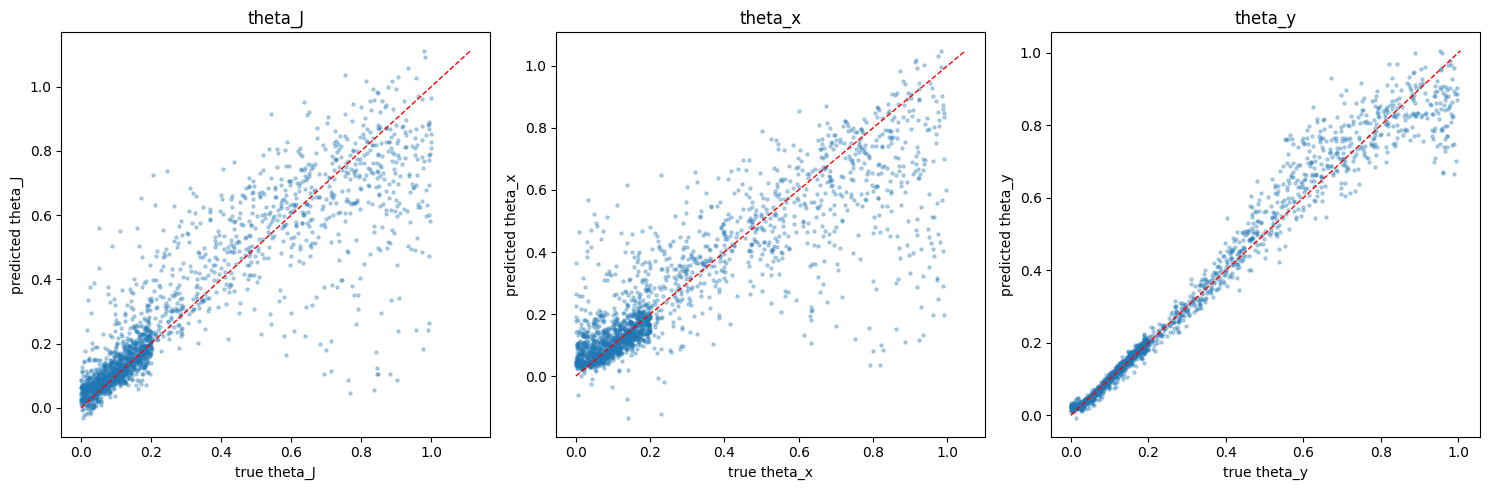

In [10]:
import matplotlib.pyplot as plt

pred_mean = samples.mean(axis=1)   # (2000, 3) -- average over the 1000 posterior samples per run
true_vals = yte.numpy()            # (2000, 3) -- ground truth for the same 2000 test runs

axis_names = ["theta_J", "theta_x", "theta_y"]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, ax in enumerate(axes):
    ax.scatter(true_vals[:, i], pred_mean[:, i], s=5, alpha=0.3)
    lims = [0, max(true_vals[:, i].max(), pred_mean[:, i].max())]
    ax.plot(lims, lims, "r--", linewidth=1)
    ax.set_xlabel(f"true {axis_names[i]}")
    ax.set_ylabel(f"predicted {axis_names[i]}")
    ax.set_title(axis_names[i])

plt.tight_layout()
plt.show()


**Finding (solved, verified): theta_J and theta_x contaminate each
other's signal; theta_y has an exclusive channel.**

The plots above show theta_y hugging the y=x line tightly while theta_J
and theta_x are visibly noisier. Two earlier explanations for this were
wrong and were removed (see git history) -- here is the version verified
end to end:

1. Built an independent first-principles replica of the whole pipeline
   (same Hamiltonian, same m_list, same 30-twirl averaging, same
   theta-draw mixture) and generated 1500 synthetic runs with the
   *theoretical* (zero shot-noise) feature values. It reproduced the real
   data's numbers almost exactly (best single-feature correlation
   0.643/0.632/0.970 for J/x/y vs. real 0.65/0.64/0.97) -- proving this is
   pure structural physics, not shot noise or a training artifact.
2. Looked at the actual curve shape: mean_Y6 vs. theta_J starts at only
   0.77 (not ~1) with high spread even at tiny theta_J, then goes
   completely flat past theta_J~0.33 (the top half of the range carries no
   signal). mean_X2 vs. theta_y starts at 0.998 with almost no spread and
   decays smoothly across the *whole* range.
3. Found the contaminant directly: holding theta_x near zero, theta_J's
   correlation with mean_Y6 jumps from -0.64 to **-0.95** -- almost as
   clean as theta_y. Symmetric for theta_x holding theta_J fixed
   (-0.63 -> -0.92). theta_y's own correlation barely moves either way
   (-0.97 vs -0.95) because nothing was ever contaminating it.

**The mechanism:** theta_J's generator (X⊗X) and theta_x's generator
(X⊗I+I⊗X) *commute* with each other (verified earlier by direct
diagonalization), so their effects merge into one shared "X-type" signal
that lands on the *same* Pauli-Y/Z features -- whatever the other one is
doing shows up as noise/saturation in that shared channel. theta_y's
generator (Y⊗I+I⊗Y) commutes with neither, so it drives its own separate
channel (Pauli-X survival) that nothing else writes over.

Full writeup: [`../analysis/findings.html`](../analysis/findings.html) §"Why theta_y is recovered so much better".

### Step 11 — Worked examples: posterior vs. truth

Pick 4 real test-set rows by their true theta_J value (near-zero, mid, the
theta&asymp;0.5 anomaly zone tied to lambda_XX=0.42, and large/saturating)
-- chosen by true value, not by how good the prediction looked, so this
isn't cherry-picked. For each, plot the model's already-computed 1000
posterior guesses (from Step 8) as a histogram per axis, with the true
answer marked and a check for whether it falls inside the model's own
68% confidence band.

In [11]:
# pick 4 rows from the existing 2000-row test set (answer key = yte), by
# true theta_J value -- not by how good the model's guess was
targets = [0.02, 0.2, 0.5, 0.85]  # near-zero, mid, anomaly zone (~lambda_XX=0.42), large/saturating
labels = ["near-zero", "mid-range", "anomaly zone (~0.5)", "large/saturating"]

true_J = yte[:, 0].numpy()
example_idx = [int(np.argmin(np.abs(true_J - t))) for t in targets]

for idx, label in zip(example_idx, labels):
    print(f"{label:>22}: row {idx}, true (theta_J,x,y) = {yte[idx].numpy().round(3)}")

             near-zero: row 1053, true (theta_J,x,y) = [0.02  0.089 0.066]
             mid-range: row 1263, true (theta_J,x,y) = [0.2   0.132 0.696]
   anomaly zone (~0.5): row 592, true (theta_J,x,y) = [0.502 0.831 0.79 ]
      large/saturating: row 1301, true (theta_J,x,y) = [0.85  0.264 0.358]


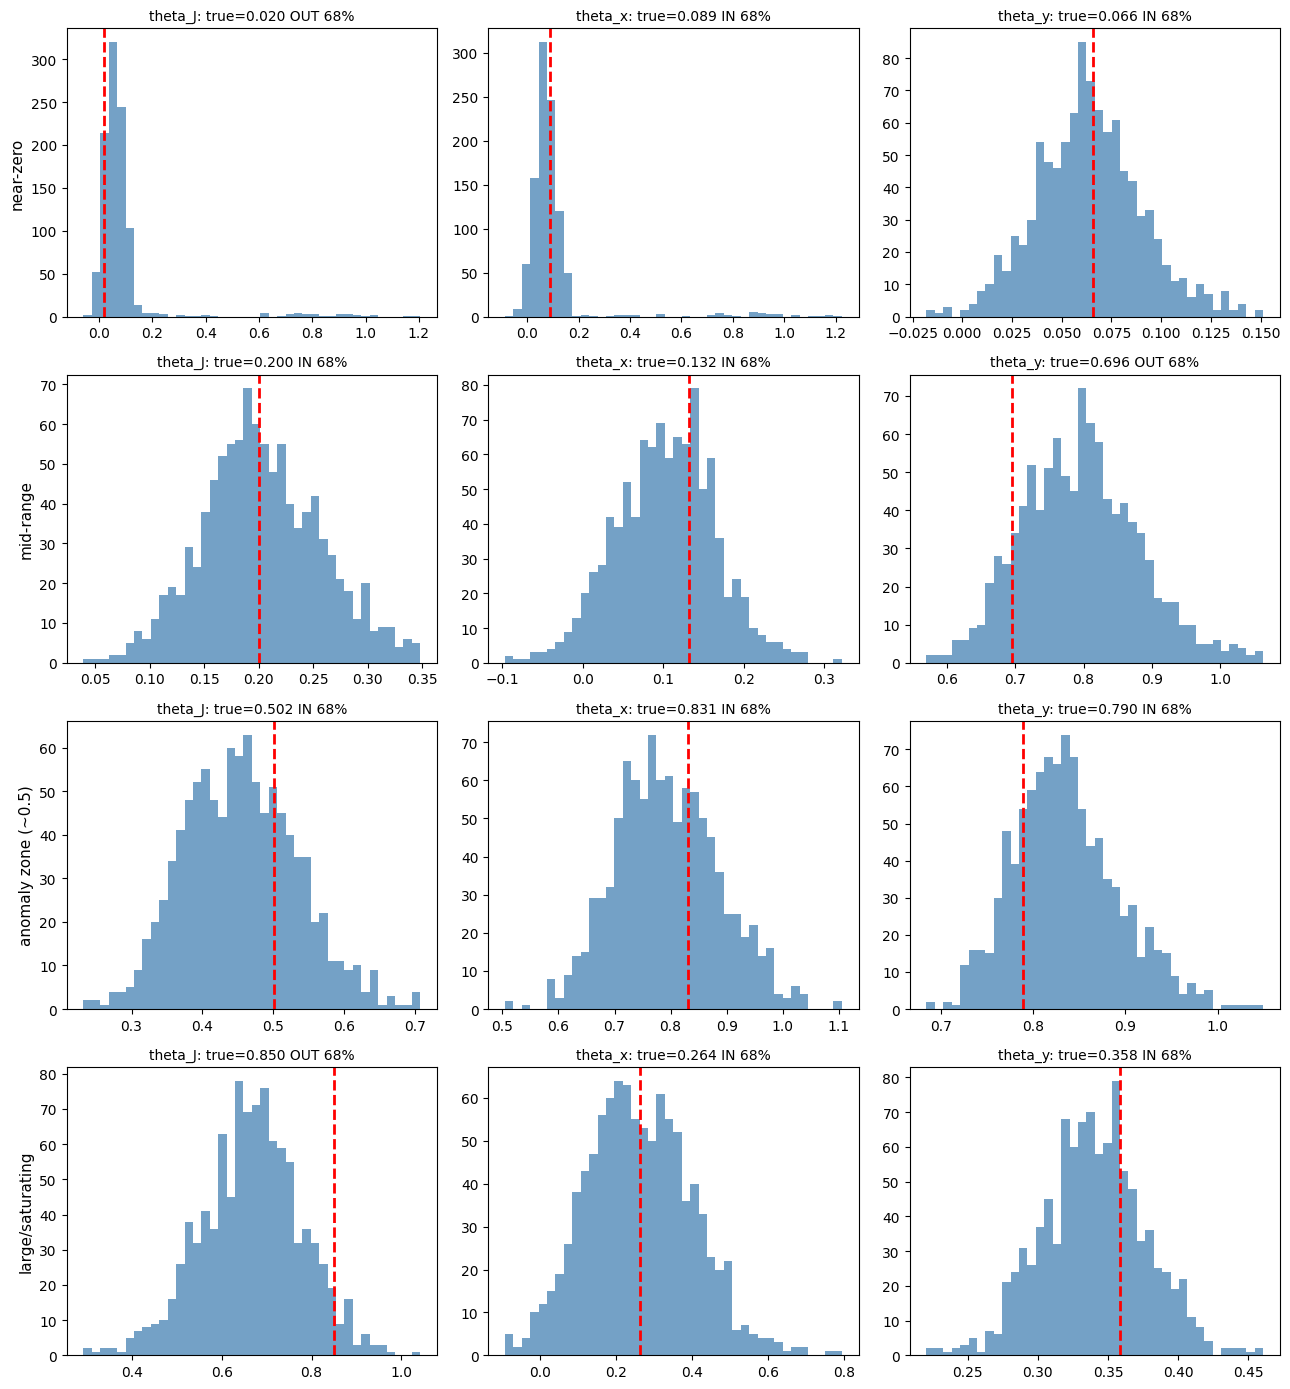

In [12]:
# for each of the 4 chosen questions, plot the model's already-made 1000
# guesses (samples, from Step 8) per axis, with the true answer marked
import matplotlib.pyplot as plt

axis_names = ["theta_J", "theta_x", "theta_y"]
fig, axes = plt.subplots(4, 3, figsize=(13, 14))

for row, (idx, label) in enumerate(zip(example_idx, labels)):
    true_vals = yte[idx].numpy()
    for col, name in enumerate(axis_names):
        ax = axes[row, col]
        cloud = samples[idx, :, col].numpy()
        ax.hist(cloud, bins=40, color="steelblue", alpha=0.75)
        ax.axvline(true_vals[col], color="red", linestyle="--", linewidth=2)
        lo, hi = np.percentile(cloud, [16, 84])
        inside = lo <= true_vals[col] <= hi
        ax.set_title(f"{name}: true={true_vals[col]:.3f} {'IN' if inside else 'OUT'} 68%", fontsize=10)
        if col == 0:
            ax.set_ylabel(label, fontsize=11)

plt.tight_layout()
plt.show()